# 11 · Adapt expressive speech

Generate a short spoken message with a prescribed delivery. Freeze the text
encoder and codec, and train low-rank updates to decoder cross-attention.
Assess whether the new decoder preserves the message and moves the delivery
rate toward the held-out reference. Use identical text and descriptions on
the frozen and adapted sides.

## 1. Start with a T4 profile

The default profile trains on four short clips and synthesizes two paired
examples in full precision. It is a compatibility and measurement run.
The full profile increases the sample and optimizer budgets. The notebook
records timings and peak allocation for the actual run.

[Read the lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/3-adapt-models/11-adapt-expressive-speech)

In [1]:
import os
import subprocess
import sys
import torch

# Parler and Whisper run in PyTorch on this runtime.
os.environ["USE_TF"] = "0"

if not torch.cuda.is_available() or "T4" not in torch.cuda.get_device_name():
    raise RuntimeError("Select a Colab T4 for this notebook.")

PARLER_CODE = "d108732cd57788ec86bc857d99a6cabd66663d68"
AUDIOTOOLS_CODE = "348ebf2034ce24e2a91a553e3171cb00c0c71678"
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q",
     "transformers==4.46.1", "datasets==3.6.0", "sentencepiece==0.2.1",
     "soundfile==0.13.1", "jiwer==4.0.0", "descript-audio-codec==1.0.0",
     f"descript-audiotools @ https://github.com/descriptinc/audiotools/archive/{AUDIOTOOLS_CODE}.tar.gz",
     "protobuf==4.25.8"],
    check=True,
)
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "--no-deps",
     f"https://github.com/huggingface/parler-tts/archive/{PARLER_CODE}.tar.gz"],
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '--no-deps', 'https://github.com/huggingface/parler-tts/archive/d108732cd57788ec86bc857d99a6cabd66663d68.tar.gz'], returncode=0)

In [2]:
from collections import Counter, defaultdict
from io import BytesIO
from math import gcd, sqrt
from pathlib import Path
from time import perf_counter
import csv
import gc
import importlib.metadata
import json
import random
import re

import jiwer
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from datasets import Audio, load_dataset
from IPython.display import FileLink, display
from parler_tts import ParlerTTSForConditionalGeneration
from parler_tts.modeling_parler_tts import build_delay_pattern_mask
from scipy.signal import resample_poly
from torch import nn
from transformers import AutoTokenizer, WhisperForConditionalGeneration, WhisperProcessor

MODEL_ID = "parler-tts/parler-tts-mini-v1"
REVISION = "0392b9451a601e528fd863bbb0598431fee810d9"
AUDIO_ID = "parler-tts/libritts_r_filtered"
AUDIO_REVISION = "8980d6531fa6404290be3ff52aeb55b95b9c8c93"
DESC_ID = "parler-tts/libritts-r-filtered-speaker-descriptions"
DESC_REVISION = "0ffbb79e07eaea6d9b191ac93a430f9264b3131d"
ASR_ID = "openai/whisper-base"
ASR_REVISION = "e37978b90ca9030d5170a5c07aadb050351a65bb"
PROFILE = os.environ.get("COURSE_PROFILE", "profile")
LIMITS = {
    "profile": {"train": 4, "test": 2, "steps": 4, "max_new_tokens": 340, "scan": 512},
    "full": {"train": 32, "test": 12, "steps": 64, "max_new_tokens": 390, "scan": 4096},
}[PROFILE]
SEED = 411
MAX_SECONDS = 3.1
MIN_SECONDS = 1.0
OUT = Path("results")
AUDIO_OUT = OUT / "audio"
AUDIO_OUT.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda")
random.seed(SEED)
torch.manual_seed(SEED)
get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['svg']")
free_bytes, _ = torch.cuda.mem_get_info()
if free_bytes < 12 * 2**30:
    raise RuntimeError("The FP32 Parler-TTS profile needs at least 12 GiB free on T4.")

## 2. Join the text, audio and delivery description

Use the published train.clean.100 and test.clean partitions of LibriTTS-R
filtered. Stream a bounded prefix and join descriptions by exact utterance
ID. Use no more than two clips per training speaker and one per test speaker;
assert the speaker populations are disjoint. Keep each held-out description
fixed across both decoders.

The checkpoint's training data includes LibriTTS-R. This split measures
what changes during our adapter stage. It cannot establish whether the
checkpoint saw a recording at pretraining time.

In [3]:
# SMOKE LIBRARY START
def canonical_text(text):
    return " ".join(re.findall(r"[a-z0-9]+", text.lower()))


def at_rate(wave, before, after):
    if before == after:
        return wave
    divisor = gcd(before, after)
    return resample_poly(wave, after // divisor, before // divisor).astype(np.float32)


def label_audio_codes(codes, bos, eos, delay_pattern):
    if codes.ndim != 4 or codes.shape[0] != 1:
        raise ValueError(f"Expected one codec frame group, got {tuple(codes.shape)}")
    tokens = codes[0].long()
    batch, codebooks, _ = tokens.shape
    first = torch.full((batch, codebooks, 1), bos, device=tokens.device, dtype=torch.long)
    inputs = torch.cat([first, tokens], dim=-1)
    _, pattern = delay_pattern(
        inputs, bos_token_id=bos, pad_token_id=eos,
        max_length=inputs.shape[-1] + codebooks, num_codebooks=codebooks,
    )
    filled = torch.where(pattern == -1, eos, pattern)
    return filled[:, 1:].reshape(batch, codebooks, -1).transpose(1, 2).contiguous()


class LinearLoRA(nn.Module):
    def __init__(self, base, rank=8, alpha=16):
        super().__init__()
        self.base = base
        self.down = nn.Linear(base.in_features, rank, bias=False, device=base.weight.device, dtype=base.weight.dtype)
        self.up = nn.Linear(rank, base.out_features, bias=False, device=base.weight.device, dtype=base.weight.dtype)
        nn.init.kaiming_uniform_(self.down.weight, a=sqrt(5))
        nn.init.zeros_(self.up.weight)
        self.scale = alpha / rank

    @property
    def weight(self):
        return self.base.weight

    def forward(self, hidden):
        return self.base(hidden) + self.scale * self.up(self.down(hidden))


def attach_decoder_lora(model, rank, alpha):
    model.requires_grad_(False)
    targets = [
        (name, layer) for name, layer in model.named_modules()
        if isinstance(layer, nn.Linear) and name.startswith("decoder.")
        and ".encoder_attn." in name and name.endswith((".q_proj", ".v_proj"))
    ]
    if not targets:
        raise RuntimeError("No decoder cross-attention query or value projections found.")
    for name, layer in targets:
        parent, _, field = name.rpartition(".")
        setattr(model.get_submodule(parent), field, LinearLoRA(layer, rank, alpha))
    return [name for name, _ in targets]


def update_decoder(model, fields, labels, trainable, optimizer):
    optimizer.zero_grad(set_to_none=True)
    loss = model(**fields, labels=labels, use_cache=False).loss
    if not torch.isfinite(loss):
        raise RuntimeError("Nonfinite Parler codec loss.")
    loss.backward()
    norm = nn.utils.clip_grad_norm_(list(trainable.values()), max_norm=1.0, error_if_nonfinite=True)
    optimizer.step()
    return {"loss": loss.item(), "gradient_norm": norm.item()}


def restore_profile_weights(trainable, initial):
    with torch.no_grad():
        for name, parameter in trainable.items():
            parameter.copy_(initial[name])
            parameter.grad = None
# SMOKE LIBRARY END

### What makes an audio example eligible?

Use one admissible clip per selected test speaker, and preserve the annotated source
and text in the input manifest. Reject mismatched descriptions before creating labels.

In [4]:
def load_aligned(split, count, cap_per_speaker):
    audio_stream = load_dataset(AUDIO_ID, "clean", split=split, revision=AUDIO_REVISION, streaming=True)
    desc_stream = load_dataset(DESC_ID, "clean", split=split, revision=DESC_REVISION, streaming=True)
    audio_stream = audio_stream.cast_column("audio", Audio(decode=False))
    clips = {}
    speaker_counts = Counter()
    for raw in audio_stream.take(LIMITS["scan"]):
        speaker = str(raw["speaker_id"])
        text = raw["text_normalized"].strip()
        if speaker_counts[speaker] >= cap_per_speaker or not (4 <= len(canonical_text(text).split()) <= 14):
            continue
        content = raw["audio"]["bytes"]
        if content is None:
            raise RuntimeError("The pinned stream did not include audio bytes.")
        wave, rate = sf.read(BytesIO(content), dtype="float32")
        if wave.ndim != 1 or not MIN_SECONDS <= len(wave) / rate <= MAX_SECONDS or not np.isfinite(wave).all():
            continue
        clip_id = str(raw["id"])
        assert clip_id not in clips
        clips[clip_id] = {"id": clip_id, "speaker": speaker, "text": text, "wave": wave, "rate": rate}
        speaker_counts[speaker] += 1
        if len(clips) == count:
            break
    if len(clips) != count:
        raise RuntimeError(f"{split}: found only {len(clips)} admissible audio clips in the bounded stream.")

    remaining = set(clips)
    for meta in desc_stream.take(20000):
        clip_id = str(meta["id"])
        if clip_id in remaining:
            description = (meta["text_description"] or "").strip()
            if (str(meta["speaker_id"]) != clips[clip_id]["speaker"] or not description
                    or canonical_text(meta["text"]) != canonical_text(clips[clip_id]["text"])):
                raise RuntimeError(f"Invalid metadata join for {clip_id}")
            clips[clip_id]["description"] = description
            remaining.remove(clip_id)
            if not remaining:
                break
    if remaining:
        raise RuntimeError(f"{split}: no matching metadata for {sorted(remaining)} in the bounded stream.")
    return list(clips.values())


train = load_aligned("train.clean.100", LIMITS["train"], cap_per_speaker=2)
test = load_aligned("test.clean", LIMITS["test"], cap_per_speaker=1)
assert {clip["speaker"] for clip in train}.isdisjoint(clip["speaker"] for clip in test)
clip_manifest = {
    split: [{k: clip[k] for k in ("id", "speaker", "text", "description")} for clip in rows]
    for split, rows in (("train", train), ("test", test))
}
(OUT / "input-manifest.json").write_text(json.dumps(clip_manifest, indent=2), encoding="utf-8")
print({split: len(rows) for split, rows in clip_manifest.items()})

{'train': 4, 'test': 2}


## 3. Encode the training targets once

The DAC encoder turns a waveform into nine codebook streams. The next-token
target offsets each stream by one more position than its predecessor. Use
the official delay-mask routine and save the cached CPU labels. Keep the
codec and text encoder in evaluation mode for every training step.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
model = ParlerTTSForConditionalGeneration.from_pretrained(
    MODEL_ID, revision=REVISION, torch_dtype=torch.float32, attn_implementation="eager",
    use_safetensors=True,
).eval().requires_grad_(False).to(device)
sample_rate = model.audio_encoder.config.sampling_rate
codebooks = model.decoder.num_codebooks
bos_token = model.config.decoder_start_token_id
eos_token = model.config.decoder.eos_token_id
assert codebooks == 9 and bos_token == 1025 and eos_token == 1024
torch.cuda.reset_peak_memory_stats()
codec_start = perf_counter()
with torch.no_grad():
    for clip in train + test:
        samples = at_rate(clip["wave"], clip["rate"], sample_rate)
        tensor = torch.from_numpy(samples)[None, None, :].to(device)
        codec = model.audio_encoder.encode(
            input_values=tensor, n_quantizers=codebooks, sample_rate=sample_rate, return_dict=True,
        )
        clip["labels"] = label_audio_codes(codec.audio_codes, bos_token, eos_token, build_delay_pattern_mask).cpu()
        assert clip["labels"].shape[-1] == codebooks
torch.cuda.synchronize()
codec_seconds = perf_counter() - codec_start
torch.save({clip["id"]: clip["labels"] for clip in train + test}, OUT / "codec-labels.pt")

### Where do the descriptions and target text go?

The free-text description conditions the encoder. The words to pronounce enter through
the prompt input. Cache the audio targets before either decoder is scored.

In [6]:
def prompt_fields(clip):
    description = tokenizer(clip["description"], return_tensors="pt").to(device)
    prompt = tokenizer(clip["text"], return_tensors="pt").to(device)
    return {"input_ids": description.input_ids, "attention_mask": description.attention_mask,
            "prompt_input_ids": prompt.input_ids, "prompt_attention_mask": prompt.attention_mask}


@torch.no_grad()
def heldout_losses():
    model.eval()
    return {clip["id"]: model(**prompt_fields(clip), labels=clip["labels"].to(device), use_cache=False).loss.item()
            for clip in test}


@torch.no_grad()
def synthesize(arm):
    model.eval()
    rows = []
    for clip in test:
        fields = prompt_fields(clip)
        torch.cuda.synchronize()
        start = perf_counter()
        generated = model.generate(
            **fields, do_sample=False, max_new_tokens=LIMITS["max_new_tokens"],
            return_dict_in_generate=True, output_scores=True,
        )
        torch.cuda.synchronize()
        seconds = perf_counter() - start
        duration_samples = int(generated.audios_length[0])
        wave = generated.sequences[0, :duration_samples].float().cpu().numpy()
        if not len(wave) or not np.isfinite(wave).all():
            raise RuntimeError(f"Synthesis returned invalid samples for {clip['id']}")
        path = AUDIO_OUT / f"{clip['id']}-{arm}.wav"
        sf.write(path, wave, sample_rate, subtype="FLOAT")
        rows.append({"id": clip["id"], "arm": arm, "audio_path": str(path), "synthesis_seconds": seconds,
                     "generation_steps": len(generated.scores),
                     "hit_token_cap": len(generated.scores) >= LIMITS["max_new_tokens"]})
    return rows

### Will the longest prepared update fit on T4?

Perform one real decoder update before the scored run. Measure the synchronised step
and its allocator peaks. Restore the initial adapter weights and discard the optimiser
state so the profile does not contribute to the scored update budget.

In [7]:
rank, alpha = 8, 16
targets = attach_decoder_lora(model, rank, alpha)
trainable = {name: parameter for name, parameter in model.named_parameters() if parameter.requires_grad}
assert len(trainable) == 2 * len(targets)
assert all(".encoder_attn." in name and name.endswith(("down.weight", "up.weight")) for name in trainable)
initial_weights = {name: parameter.detach().cpu().clone() for name, parameter in trainable.items()}
probe_optimizer = torch.optim.AdamW(trainable.values(), lr=5e-5)
probe = max(train, key=lambda clip: (clip["labels"].shape[1], len(clip["description"])))
model.train()
model.audio_encoder.eval()
model.text_encoder.eval()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
started = perf_counter()
probe_metrics = update_decoder(model, prompt_fields(probe), probe["labels"].to(device), trainable, probe_optimizer)
torch.cuda.synchronize()
t4_profile = {
    "utterance_id": probe["id"], "codec_sequence_length": probe["labels"].shape[1],
    "seconds": perf_counter() - started,
    "peak_allocated_gib": torch.cuda.max_memory_allocated() / 2**30,
    "peak_reserved_gib": torch.cuda.max_memory_reserved() / 2**30,
    **probe_metrics,
}
restore_profile_weights(trainable, initial_weights)
del probe_optimizer, initial_weights
gc.collect()
torch.cuda.empty_cache()
torch.manual_seed(SEED)
(OUT / "11-t4-profile.json").write_text(json.dumps(t4_profile, indent=2), encoding="utf-8")
print(json.dumps(t4_profile, indent=2))
if (t4_profile["seconds"] > 50 or t4_profile["peak_allocated_gib"] > 11
        or t4_profile["peak_reserved_gib"] > min(13, free_bytes / 2**30 - 1)):
    raise RuntimeError("T4 training profile exceeds its registered limits.")
torch.cuda.reset_peak_memory_stats()

{
  "utterance_id": "730_358_000003_000002",
  "codec_sequence_length": 260,
  "seconds": 0.7261192790010682,
  "peak_allocated_gib": 3.8101987838745117,
  "peak_reserved_gib": 3.830078125,
  "loss": 4.73482084274292,
  "gradient_norm": 0.007110423408448696
}


### What does the frozen decoder sound like?

The initial adapters add zero to the frozen model's projections. Synthesize on the common
inputs before fitting the restored weights and save the original recordings for comparison.

In [8]:
for clip in test:
    path = AUDIO_OUT / f"{clip['id']}-reference.wav"
    sf.write(path, clip["wave"], clip["rate"], subtype="FLOAT")

torch.cuda.synchronize()
teacher_forced_frozen = heldout_losses()
rows = synthesize("frozen")

## 4. Adapt how the decoder reads its conditioning

Add low-rank matrices to query and value projections in decoder
cross-attention. The zero-initialized output matrix leaves the original
function unchanged before training. Optimize codec token likelihood under
the original delivery description and text. Keep one utterance per step
and train in FP32 to avoid FP16 overflow in the frozen text encoder.

In [9]:
optimizer = torch.optim.AdamW(trainable.values(), lr=5e-5)
train_rows = []
schedule = list(train)
random.Random(SEED).shuffle(schedule)
model.train()
model.audio_encoder.eval()
model.text_encoder.eval()
train_start = perf_counter()
for step in range(LIMITS["steps"]):
    clip = schedule[step % len(schedule)]
    metrics = update_decoder(model, prompt_fields(clip), clip["labels"].to(device), trainable, optimizer)
    train_rows.append({"step": step + 1, "id": clip["id"], **metrics})
torch.cuda.synchronize()
training_seconds = perf_counter() - train_start
assert any(p.detach().count_nonzero().item() for name, p in trainable.items() if name.endswith("up.weight"))

parameter_count = sum(p.numel() for p in trainable.values())
torch.save(
    {"rank": rank, "alpha": alpha, "targets": targets, "model": MODEL_ID, "revision": REVISION,
     "weights": {name: p.detach().cpu() for name, p in trainable.items()}},
    OUT / "decoder-cross-attention-lora.pt",
)
teacher_forced_adapted = heldout_losses()
rows.extend(synthesize("adapted"))
tts_peak = torch.cuda.max_memory_allocated()

## 5. Score intelligibility and timing separately

Release Parler-TTS from the GPU before loading Whisper. Transcribe every
generated and recorded clip with the same frozen settings. ASR error is an
intelligibility proxy subject to the recognizer's own mistakes. Compare
absolute error in expected words per minute against the recorded reference.
Duration and rate do not certify fidelity to the entire style description.

In [10]:
del model, optimizer, trainable, codec, tensor
gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

asr_processor = WhisperProcessor.from_pretrained(ASR_ID, revision=ASR_REVISION)
asr = WhisperForConditionalGeneration.from_pretrained(
    ASR_ID, revision=ASR_REVISION, torch_dtype=torch.float16,
).eval().requires_grad_(False).to(device)
asr.generation_config.forced_decoder_ids = None
asr_rate = asr_processor.feature_extractor.sampling_rate


@torch.no_grad()
def transcribe(wave, rate):
    seconds = len(wave) / rate
    if seconds < 0.1:
        return ""
    inputs = asr_processor(
        at_rate(wave, rate, asr_rate), sampling_rate=asr_rate, return_tensors="pt",
        return_attention_mask=True,
    ).to(device, dtype=torch.float16)
    tokens = asr.generate(**inputs, language="en", task="transcribe", do_sample=False,
                          num_beams=1, max_new_tokens=72)
    return asr_processor.batch_decode(tokens, skip_special_tokens=True)[0]


test_by_id = {clip["id"]: clip for clip in test}

### What changed on the same utterance?

Preserve each utterance ID across the frozen, adapted and recorded arms. Log transcript,
approximate rate, duration and generation-cap status for individual comparisons.

In [11]:
for clip in test:
    rows.append({"id": clip["id"], "arm": "recorded-reference",
                 "audio_path": str(AUDIO_OUT / f"{clip['id']}-reference.wav"),
                 "synthesis_seconds": None, "generation_steps": None, "hit_token_cap": None})

losses = {"frozen": teacher_forced_frozen, "adapted": teacher_forced_adapted}
for row in rows:
    clip = test_by_id[row["id"]]
    wave, rate = sf.read(row["audio_path"], dtype="float32")
    transcript = transcribe(wave, rate)
    reference = canonical_text(clip["text"])
    found = jiwer.process_words(reference, canonical_text(transcript))
    ref_duration = len(clip["wave"]) / clip["rate"]
    duration = len(wave) / rate
    words = len(reference.split())
    words_per_minute = 60 * words / duration if duration >= .1 else None
    ref_words_per_minute = 60 * words / ref_duration
    row.update({
        "text": clip["text"], "description": clip["description"], "asr": transcript,
        "reference_words": words, "word_edits": found.substitutions + found.deletions + found.insertions,
        "audio_seconds": duration, "reference_seconds": ref_duration,
        "absolute_duration_error": abs(duration - ref_duration),
        "words_per_minute": words_per_minute,
        "absolute_rate_error": abs(words_per_minute - ref_words_per_minute) if words_per_minute is not None else None,
        "real_time_factor": row["synthesis_seconds"] / duration if row["synthesis_seconds"] is not None else None,
        "teacher_forced_codec_loss": losses.get(row["arm"], {}).get(row["id"]),
    })


def summarize(arm_rows):
    rates = [row["absolute_rate_error"] for row in arm_rows if row["absolute_rate_error"] is not None]
    factors = [row["real_time_factor"] for row in arm_rows if row["real_time_factor"] is not None]
    return {
        "clips": len(arm_rows),
        "asr_wer": sum(r["word_edits"] for r in arm_rows) / sum(r["reference_words"] for r in arm_rows),
        "mean_absolute_duration_error": float(np.mean([r["absolute_duration_error"] for r in arm_rows])),
        "median_absolute_rate_error": float(np.median(rates)) if rates else None,
        "rate_examples": len(rates),
        "median_synthesis_real_time_factor": float(np.median(factors)) if factors else None,
        "clips_at_token_cap": sum(r["hit_token_cap"] is True for r in arm_rows),
        "clips_under_100ms": sum(r["audio_seconds"] < .1 for r in arm_rows),
    }


by_arm = defaultdict(list)
for row in rows:
    by_arm[row["arm"]].append(row)
assert all({r["id"] for r in arm} == set(test_by_id) for arm in by_arm.values())
scores = {arm: summarize(arm_rows) for arm, arm_rows in by_arm.items()}
report = {
    "gpu": torch.cuda.get_device_name(), "cuda": torch.version.cuda, "profile": PROFILE, "limits": LIMITS,
    "checkpoint": [MODEL_ID, REVISION], "asr_checkpoint": [ASR_ID, ASR_REVISION],
    "audio_data": [AUDIO_ID, AUDIO_REVISION], "descriptions": [DESC_ID, DESC_REVISION],
    "parler_code": PARLER_CODE, "audiotools_code": AUDIOTOOLS_CODE,
    "seed": SEED, "codec_seconds": codec_seconds, "training_seconds": training_seconds,
    "training_parameters": parameter_count, "adapter_targets": targets, "t4_profile": t4_profile,
    "tts_peak_allocated_bytes": tts_peak, "asr_peak_allocated_bytes": torch.cuda.max_memory_allocated(),
    "packages": {p: importlib.metadata.version(p) for p in
                 ("torch", "transformers", "datasets", "parler-tts", "descript-audio-codec", "descript-audiotools", "jiwer")},
    "scores": scores,
}
(OUT / "report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
(OUT / "train.jsonl").write_text("".join(json.dumps(r) + "\n" for r in train_rows), encoding="utf-8")
with (OUT / "clips.csv").open("w", newline="", encoding="utf-8") as f:
    csv_writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    csv_writer.writeheader()
    csv_writer.writerows(rows)
print(json.dumps(report, indent=2))

{
  "gpu": "Tesla T4",
  "cuda": "13.0",
  "profile": "profile",
  "limits": {
    "train": 4,
    "test": 2,
    "steps": 4,
    "max_new_tokens": 340,
    "scan": 512
  },
  "checkpoint": [
    "parler-tts/parler-tts-mini-v1",
    "0392b9451a601e528fd863bbb0598431fee810d9"
  ],
  "asr_checkpoint": [
    "openai/whisper-base",
    "e37978b90ca9030d5170a5c07aadb050351a65bb"
  ],
  "audio_data": [
    "parler-tts/libritts_r_filtered",
    "8980d6531fa6404290be3ff52aeb55b95b9c8c93"
  ],
  "descriptions": [
    "parler-tts/libritts-r-filtered-speaker-descriptions",
    "0ffbb79e07eaea6d9b191ac93a430f9264b3131d"
  ],
  "parler_code": "d108732cd57788ec86bc857d99a6cabd66663d68",
  "audiotools_code": "348ebf2034ce24e2a91a553e3171cb00c0c71678",
  "seed": 411,
  "codec_seconds": 3.929688611000529,
  "training_seconds": 0.6863759829993796,
  "training_parameters": 786432,
  "adapter_targets": [
    "decoder.model.decoder.layers.0.encoder_attn.v_proj",
    "decoder.model.decoder.layers.0.encoder_

### Which findings should you take into a listening review?

Start with the intended words. Listen across all three WAV files for pacing and
intelligibility. At two held-out examples, describe each utterance alongside the aggregate.

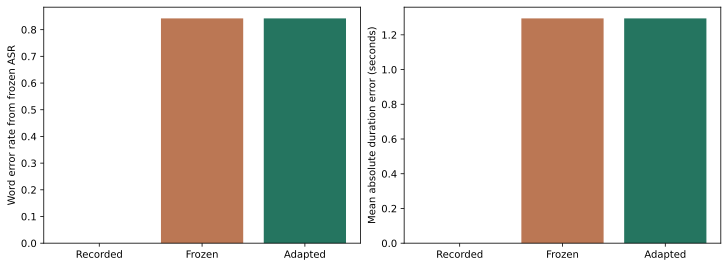

He dropped back heavily into his chair by the fire.
A female speaker delivers her very monotone and slightly low-pitch words quickly in a nearly quiet environment. The recording captures her speech with exceptional clarity.
recorded-reference 2.32  He dropped back heavily into his chair by the fire.


/content/advanced-fine-tuning-runs/11-adapt-expressive-speech-e926c5765e00-zdybkh4e/results/audio/4446_2275_000024_000000-reference.wav

frozen 3.8545124716553287  He dropped.


/content/advanced-fine-tuning-runs/11-adapt-expressive-speech-e926c5765e00-zdybkh4e/results/audio/4446_2275_000024_000000-frozen.wav

adapted 3.8545124716553287  He dropped.


/content/advanced-fine-tuning-runs/11-adapt-expressive-speech-e926c5765e00-zdybkh4e/results/audio/4446_2275_000024_000000-adapted.wav

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
names = ["Recorded", "Frozen", "Adapted"]
keys = ["recorded-reference", "frozen", "adapted"]
colors = ["#6b7c74", "#bb7754", "#257560"]
axes[0].bar(names, [scores[key]["asr_wer"] for key in keys], color=colors)
axes[0].set_ylabel("Word error rate from frozen ASR")
axes[1].bar(names, [scores[key]["mean_absolute_duration_error"] for key in keys], color=colors)
axes[1].set_ylabel("Mean absolute duration error (seconds)")
fig.savefig(OUT / "speech-comparison.svg")
plt.show()

case_id = test[0]["id"]
print(test[0]["text"])
print(test[0]["description"])
for arm in keys:
    example = next(row for row in by_arm[arm] if row["id"] == case_id)
    print(arm, example["audio_seconds"], example["asr"])
    display(FileLink(example["audio_path"]))

## Read the result

Listen to both synthetic clips beside the recording. Check text fidelity,
pacing and whether audio stopped at the token budget. If the two generated
voices differ in rate, confirm that closeness to the reference coincides with
the intended delivery. A short run with public audiobook clips demonstrates
the measurement setup. Release confidence would require representative
licensed recordings, more speakers and independent listening ratings.

[Parler-TTS model card](https://huggingface.co/parler-tts/parler-tts-mini-v1) ·
[Official training guide](https://github.com/huggingface/parler-tts/tree/d108732cd57788ec86bc857d99a6cabd66663d68/training) ·
[LibriTTS-R paper](https://arxiv.org/abs/2305.18802) ·
[Course lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/3-adapt-models/11-adapt-expressive-speech)